In [1]:
import cv2 as cv
import matplotlib.pyplot as plt

In [3]:
image = cv.imread("../../data/raw/images/giraffe-Kenya.png")

In [4]:
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

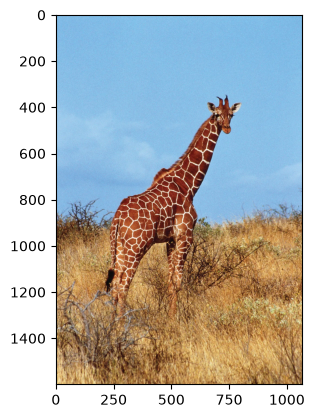

In [5]:
plt.imshow(image_rgb)

# Image Resizing

Image resizing means changing an image to a specific **width** and **height**.

## Key idea
- Resizing changes the dimensions directly.
- It does **not always preserve** the aspect ratio.
- Because of that, the image can look stretched or squeezed.

## Example
- Standard resolution: `640 x 480` (`4:3`)
- HD resolution: `1280 x 720` (`16:9`)

If we force an image from one shape into another shape without preserving proportions, that is resizing.

## Why we resize images
- to match a required input size
- to prepare thumbnails or fixed-size outputs
- to normalize image dimensions before further processing


In [6]:
print(image_rgb.shape)

(1600, 1067, 3)


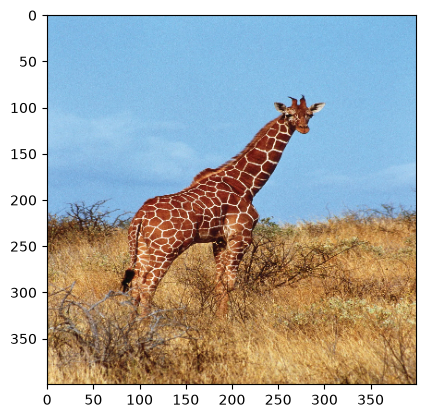

In [7]:
new_height, new_width = 400, 400

resized_image = cv.resize(image_rgb, (new_width, new_height))

plt.imshow(resized_image)

# Image Scaling

Image scaling is a type of resizing where the **aspect ratio is preserved**.

## Key idea
- Width and height are changed proportionally.
- The image keeps its natural shape.
- Scaling can be done in both directions.

## Upscaling vs Downscaling
- **Upscaling**: smaller image to larger image
- **Downscaling**: larger image to smaller image

## Example
- HD: `1280 x 720`
- Full HD: `1920 x 1080`

Both have aspect ratio `16:9`, so moving between them is scaling.

## Why scaling is useful
- reduces storage and memory usage
- helps in faster transmission
- keeps visual proportions intact
- useful for ML pipelines where all inputs should have the same shape style without distortion


(800, 533, 3)


Text(0.5, 1.0, 'Scaled image')

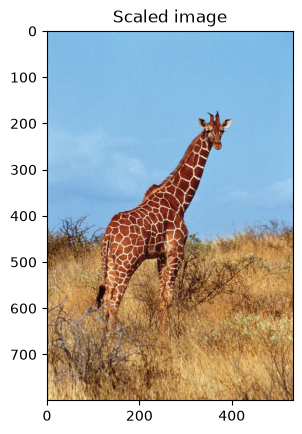

In [8]:
scale_percentage = 50
s_width = int(image_rgb.shape[1] * scale_percentage / 100)
s_height = int(image_rgb.shape[0] * scale_percentage / 100)

scaled_image = cv.resize(image_rgb, (s_width, s_height), interpolation=cv.INTER_AREA)

print(scaled_image.shape)

plt.imshow(scaled_image)
plt.title("Scaled image")

# Interpolation

Interpolation decides **how new pixel values are computed** when an image is enlarged or reduced.

## Why interpolation is needed
- In **upscaling**, new pixels must be created.
- In **downscaling**, multiple old pixels may need to be combined into fewer pixels.

So interpolation controls the final smoothness, sharpness, and quality of the resized image.

## OpenCV interpolation methods used here
- `cv2.INTER_NEAREST`: picks the nearest pixel, very fast but pixelated
- `cv2.INTER_LINEAR`: uses nearby pixels, smoother than nearest
- `cv2.INTER_CUBIC`: uses more neighboring pixels, smoother and higher quality
- `cv2.INTER_AREA`: useful especially while shrinking images
- `cv2.INTER_LANCZOS4`: high-quality output but more computationally expensive

## Practical takeaway
- choose **simpler interpolation** when speed matters
- choose **cubic** or **Lanczos4** when visual quality matters more
- nearest-neighbor is simple, but usually gives blocky edges during enlargement


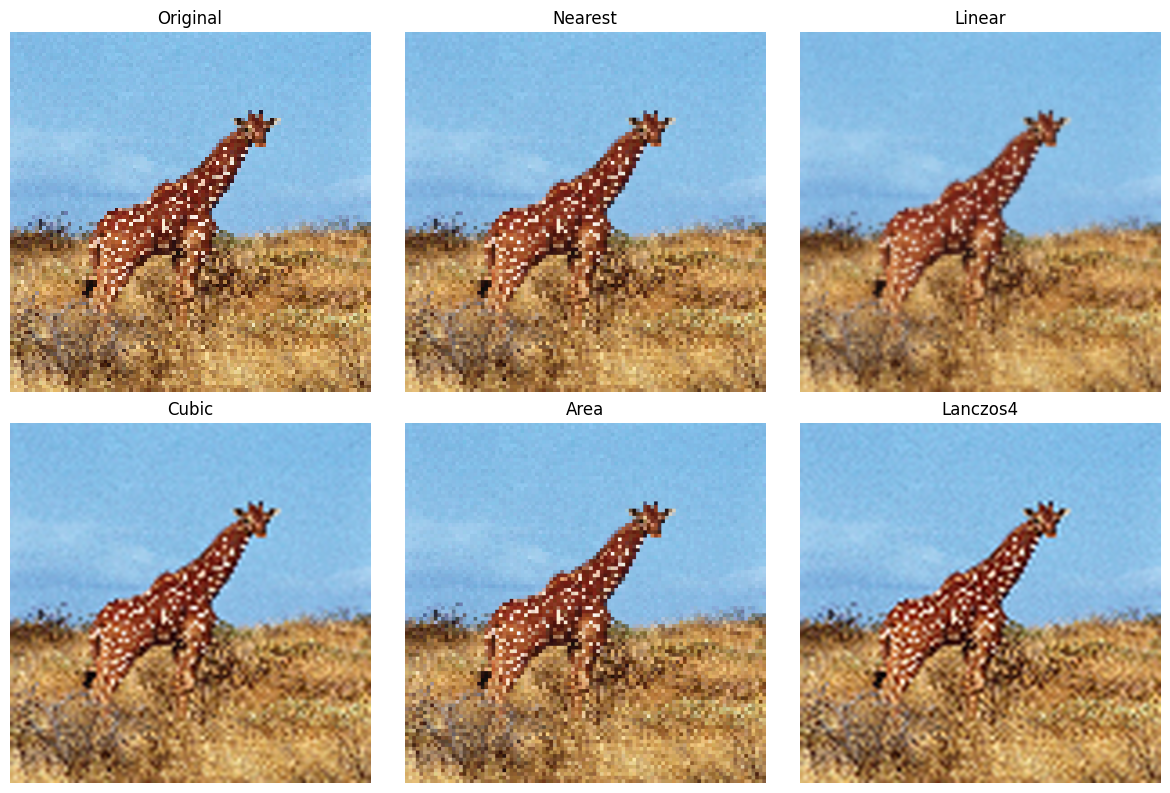

In [10]:
# image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

resize_width = 600
resize_height = 600

image_rgb_resized = cv2.resize(image_rgb, (100, 100))

# interpolation methods
methods = {
    'Nearest' : cv2.INTER_NEAREST,
    'Linear' : cv2.INTER_LINEAR,
    'Cubic' : cv2.INTER_CUBIC,
    'Area' : cv2.INTER_AREA,
    'Lanczos4' : cv2.INTER_LANCZOS4
}

resized_images = {}
for name, method in methods.items():
    resized_images[name] = cv2.resize(image_rgb_resized, (resize_width, resize_height), interpolation=method)
    cv2.imwrite(f"./{name}.jpg", resized_images[name])

plt.figure(figsize=(12, 8))

#  Original image
plt.subplot(2, 3, 1)
plt.imshow(image_rgb_resized)
plt.title("Original")
plt.axis('off')

for i, (name, resized_image) in enumerate(resized_images.items(), start=2):
    plt.subplot(2,3,i)
    plt.imshow( resized_image)
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Quick Summary

- **Resizing**: changes width and height directly
- **Scaling**: resizes while preserving aspect ratio
- **Upscaling**: smaller to larger
- **Downscaling**: larger to smaller
- **Interpolation**: decides how pixels are adjusted during resizing

A good rule of thumb is:

- use resizing when a fixed output size is required
- use scaling when you want to keep image proportions
- use better interpolation methods when image quality is important
